# 1. Подготовка к анализу

Цель исследования — изучить структуру датасета Tennessee Eastman
Process, проанализировать временные ряды технологических параметров
и определить особенности нормальных и неисправных режимов.

Датасет: Tennessee Eastman Process

Задача проекта: одноклассовый поиск новизны во временных рядах
инженерной системы.

## Иморт библиотек

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadr
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)


DATA_DIR = Path("../data/raw")

### Проверка файлов


In [5]:
for path in sorted(DATA_DIR.glob("*.Rdata")):
    print(f"{path.name}: {path.stat().st_size / 1024**2:.1f} MB")

TEP_FaultFree_Testing.RData: 45.1 MB
TEP_FaultFree_Training.RData: 23.5 MB
TEP_Faulty_Testing.RData: 798.1 MB
TEP_Faulty_Training.RData: 471.2 MB


## Загружаем датасет

In [6]:
result = pyreadr.read_r(DATA_DIR / "TEP_FaultFree_Training.RData")

print("Объекты внутри файла:", list(result.keys()))

df_normal = next(iter(result.values()))

print("Размер:", df_normal.shape)
display(df_normal.head())

Объекты внутри файла: ['fault_free_training']
Размер: (250000, 55)


,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,xmeas_8,xmeas_9,xmeas_10,xmeas_11,xmeas_12,xmeas_13,xmeas_14,xmeas_15,xmeas_16,xmeas_17,xmeas_18,xmeas_19,xmeas_20,xmeas_21,xmeas_22,xmeas_23,xmeas_24,xmeas_25,xmeas_26,xmeas_27,xmeas_28,xmeas_29,xmeas_30,xmeas_31,xmeas_32,xmeas_33,xmeas_34,xmeas_35,xmeas_36,xmeas_37,xmeas_38,xmeas_39,xmeas_40,xmeas_41,xmv_1,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,0.0,1.0,1,0.25038,3674.0,4529.0,9.2320,26.889,42.402,2704.3,74.863,120.41,0.33818,80.044,51.435,2632.9,25.029,50.528,3101.1,22.819,65.732,229.61,341.22,94.640,77.047,32.188,8.8933,26.383,6.8820,18.776,1.6567,32.958,13.823,23.978,1.2565,18.579,2.2633,4.8436,2.2986,0.017866,0.8357,0.098577,53.724,43.828,62.881,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.510,41.258,18.447
1,0.0,1.0,2,0.25109,3659.4,4556.6,9.4264,26.721,42.576,2705.0,75.000,120.41,0.33620,80.078,50.154,2633.8,24.419,48.772,3102.0,23.333,65.716,230.54,341.30,94.595,77.434,32.188,8.8933,26.383,6.8820,18.776,1.6567,32.958,13.823,23.978,1.2565,18.579,2.2633,4.8436,2.2986,0.017866,0.8357,0.098577,53.724,43.828,63.132,53.414,24.588,59.259,22.084,40.176,38.554,43.692,47.427,41.359,17.194
2,0.0,1.0,3,0.25038,3660.3,4477.8,9.4426,26.875,42.070,2706.2,74.771,120.42,0.33563,80.220,50.302,2635.5,25.244,50.071,3103.5,21.924,65.732,230.08,341.38,94.605,77.466,31.767,8.7694,26.095,6.8259,18.961,1.6292,32.985,13.742,23.897,1.3001,18.765,2.2602,4.8543,2.3900,0.017866,0.8357,0.098577,53.724,43.828,63.117,54.357,24.666,61.275,22.380,40.244,38.990,46.699,47.468,41.199,20.530
3,0.0,1.0,4,0.24977,3661.3,4512.1,9.4776,26.758,42.063,2707.2,75.224,120.39,0.33553,80.305,49.990,2635.6,23.268,50.435,3102.8,22.948,65.781,227.91,341.71,94.473,77.443,31.767,8.7694,26.095,6.8259,18.961,1.6292,32.985,13.742,23.897,1.3001,18.765,2.2602,4.8543,2.3900,0.017866,0.8357,0.098577,53.724,43.828,63.100,53.946,24.725,59.856,22.277,40.257,38.072,47.541,47.658,41.643,18.089
4,0.0,1.0,5,0.29405,3679.0,4497.0,9.3381,26.889,42.650,2705.1,75.388,120.39,0.32632,80.064,51.310,2632.4,26.099,50.480,3103.5,22.808,65.788,231.37,341.11,94.678,76.947,32.322,8.5821,26.769,6.8688,18.782,1.6396,33.071,13.834,24.228,1.0938,18.666,2.2193,4.8304,2.2416,0.017866,0.8357,0.098577,53.724,43.828,63.313,53.658,28.797,60.717,21.947,39.144,41.955,47.645,47.346,41.507,18.461


## 2. Общие характеристики

In [7]:
df_normal.info()

display(df_normal.describe().T)

print("\nКоличество пропусков:", df_normal.isna().sum().sum())

print("Количество дубликатов:", df_normal.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 55 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   faultNumber    250000 non-null  float64
 1   simulationRun  250000 non-null  float64
 2   sample         250000 non-null  int32  
 3   xmeas_1        250000 non-null  float64
 4   xmeas_2        250000 non-null  float64
 5   xmeas_3        250000 non-null  float64
 6   xmeas_4        250000 non-null  float64
 7   xmeas_5        250000 non-null  float64
 8   xmeas_6        250000 non-null  float64
 9   xmeas_7        250000 non-null  float64
 10  xmeas_8        250000 non-null  float64
 11  xmeas_9        250000 non-null  float64
 12  xmeas_10       250000 non-null  float64
 13  xmeas_11       250000 non-null  float64
 14  xmeas_12       250000 non-null  float64
 15  xmeas_13       250000 non-null  float64
 16  xmeas_14       250000 non-null  float64
 17  xmeas_15       250000 non-null  float64


,count,mean,std,min,25%,50%,75%,max
faultNumber,250000.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
simulationRun,250000.0,250.500000,144.337567,1.000000,125.750000,250.500000,375.250000,500.000000
sample,250000.0,250.500000,144.337567,1.000000,125.750000,250.500000,375.250000,500.000000
xmeas_1,250000.0,0.250482,0.030873,0.122450,0.229770,0.250510,0.271200,0.391740
xmeas_2,250000.0,3663.785706,34.006357,3511.800000,3640.800000,3663.700000,3686.800000,3808.400000
xmeas_3,250000.0,4508.819790,39.215420,4336.900000,4482.400000,4508.800000,4535.300000,4683.700000
xmeas_4,250000.0,9.347101,0.085721,8.972700,9.289300,9.347100,9.405100,9.729800
xmeas_5,250000.0,26.902196,0.211485,25.951000,26.758000,26.902000,27.046000,27.818000
xmeas_6,250000.0,42.337598,0.218513,41.394000,42.188000,42.338000,42.487000,43.257000
xmeas_7,250000.0,2705.037865,7.525596,2672.300000,2700.100000,2705.000000,2710.000000,2739.100000



Количество пропусков: 0
Количество дубликатов: 0


## Описание датасета


**Tennessee Eastman Process (TEP)** — набор данных, полученный в результате компьютерного моделирования промышленного химического процесса. Он широко используется для исследования методов обнаружения аномалий и диагностики неисправностей в сложных технологических системах.

Моделируемая установка предназначена для получения двух жидких продуктов (G и H) из газообразного сырья. Технологический процесс включает пять основных узлов:

1. **Реактор** — проведение химических реакций с выделением тепла.
2. **Конденсатор** — охлаждение и частичная конденсация продуктов реакции.
3. **Сепаратор** — разделение газовой и жидкой фаз.
4. **Компрессор** — возврат непрореагировавших газов в технологический цикл.
5. **Стриппер** — удаление остаточных летучих компонентов из жидкого продукта.

Установка оснащена системой автоматического управления, которая регулирует технологические параметры: температуру, давление, расходы веществ и уровни жидкости.

## Структура датасета

Датасет содержит **52 технологические переменные**, разделённые на две группы:

- **XMEAS (41 переменная)** — измеряемые параметры процесса: температуры, давления, расходы, уровни жидкости, мощность компрессора и химический состав потоков.
- **XMV (11 переменных)** — управляющие воздействия, преимущественно положения регулирующих клапанов подачи сырья, охлаждающей воды и других технологических потоков.

Дополнительно присутствуют три служебных столбца:

- `faultNumber` — номер моделируемой неисправности (0 — нормальная работа).
- `simulationRun` — идентификатор независимого запуска моделирования.
- `sample` — порядковый номер измерения внутри запуска.

Таким образом, каждый набор данных содержит **55 столбцов**, из которых 52 являются признаками технологического процесса.

Измерения сохраняются с интервалом **3 минуты**, что позволяет анализировать изменение параметров установки во времени.

Датасет включает сценарии нормальной работы и 20 типов технологических неисправностей, среди которых изменение состава сырья, нарушения охлаждения, отклонения температуры и неисправности регулирующих клапанов.


Ниже представлена схема оборудования

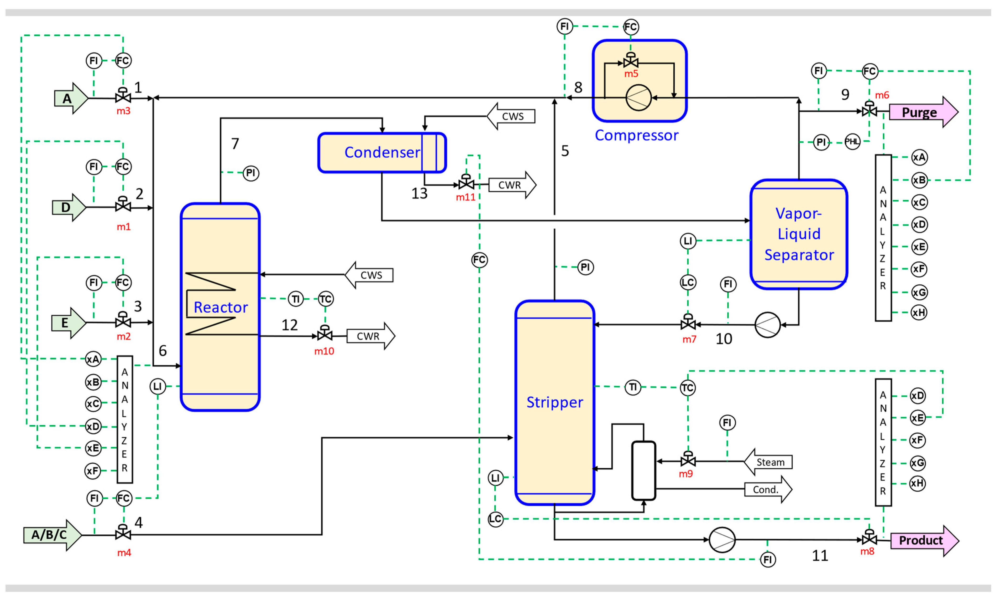
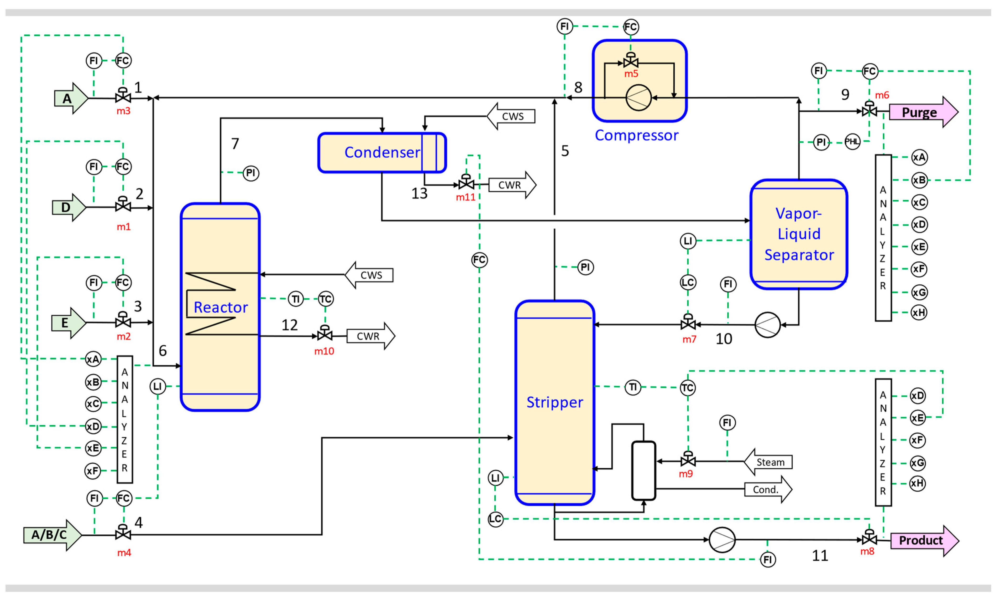
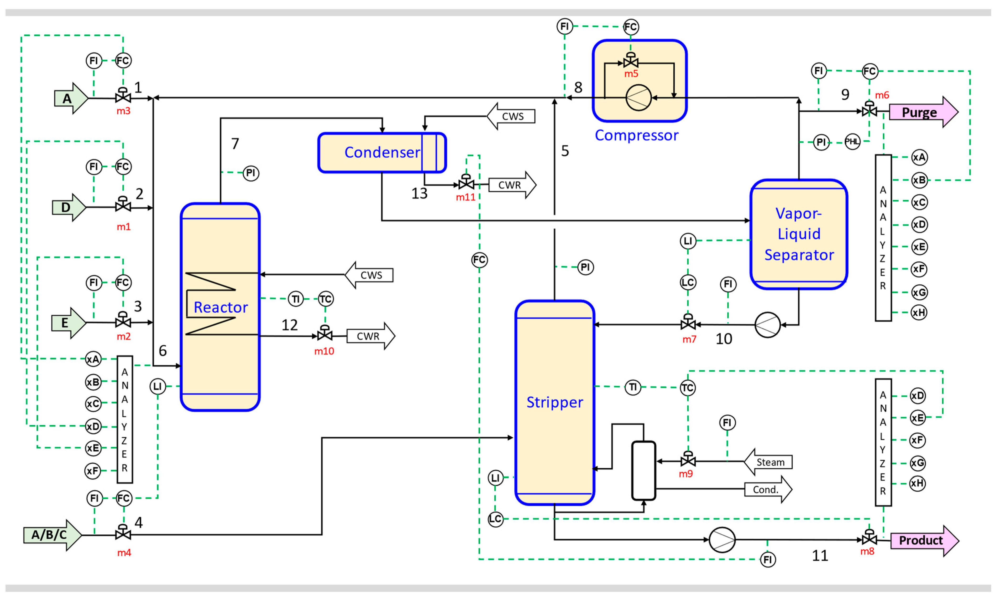

# 3. Структура временных рядов

В данном разделе исследуется количество отдельных прогонов
симуляции, их продолжительность и структура измеряемых параметров.

In [8]:
# служебные столбцы
meat_cols = ["faultNumber", "simulationRun", "sample"]

# Технологические параметры
feature_cols = [col for col in df_normal.columns if col not in meat_cols]

print("Количество тех. параметров:", len(feature_cols))
print("Кол. прогонов:", df_normal["simulationRun"].nunique())

run_lengths = df_normal.groupby("simulationRun").size()

display(run_lengths.describe())

print("Уникальные длины прогонов:", df_normal["simulationRun"].nunique())
print("Значения faultNumber:", df_normal["faultNumber"].nunique())

Количество тех. параметров: 52
Кол. прогонов: 500


count    500.0
mean     500.0
std        0.0
min      500.0
25%      500.0
50%      500.0
75%      500.0
max      500.0
dtype: float64

Уникальные длины прогонов: 500
Значения faultNumber: 1


Проверим что внутри каждого прогона отсчеты уникальны

In [9]:
duplicates = df_normal.duplicated(subset=["simulationRun", "sample"]).sum()

print("Повторяющиеся пары (прогон, отсчёт):", duplicates)

Повторяющиеся пары (прогон, отсчёт): 0


## 4. Статистический анализ технологических параметров

Исследуются диапазоны значений, средние величины и изменчивость
технологических параметров при нормальной работе установки.

In [10]:
stats = df_normal[feature_cols].agg(["mean", "std", "min", "max"]).T

stats["range"] = stats["max"] - stats["min"]

display(stats.round(3))

,mean,std,min,max,range
xmeas_1,0.250,0.031,0.122,0.392,0.269
xmeas_2,3663.786,34.006,3511.800,3808.400,296.600
xmeas_3,4508.820,39.215,4336.900,4683.700,346.800
xmeas_4,9.347,0.086,8.973,9.730,0.757
xmeas_5,26.902,0.211,25.951,27.818,1.867
xmeas_6,42.338,0.219,41.394,43.257,1.863
xmeas_7,2705.038,7.526,2672.300,2739.100,66.800
xmeas_8,75.000,0.542,72.649,77.514,4.865
xmeas_9,120.400,0.019,120.310,120.480,0.170
xmeas_10,0.337,0.013,0.285,0.395,0.110


Признаки с минимальной изменчивостью

In [11]:
display(stats.sort_values("std").head(10))

,mean,std,min,max,range
xmeas_37,0.017879,0.009943,-0.021217,0.055001,0.076218
xmeas_39,0.098532,0.010028,0.060641,0.137180,0.076539
xmeas_10,0.337055,0.012529,0.285180,0.394800,0.109620
xmeas_38,0.835705,0.018453,0.759230,0.927530,0.168300
xmeas_9,120.400022,0.019109,120.310000,120.480000,0.170000
xmeas_28,1.656808,0.025609,1.554900,1.766100,0.211200
xmeas_34,2.263296,0.026565,2.150400,2.369000,0.218600
xmeas_1,0.250482,0.030873,0.122450,0.391740,0.269290
xmeas_36,2.298254,0.053309,2.077000,2.524500,0.447500
xmeas_35,4.843786,0.066261,4.531100,5.141700,0.610600


Проверим есть ли пустые признаки

In [12]:
constant_cols = [col for col in feature_cols if df_normal[col].nunique() <= 1]

print("Постоянные признаки:", constant_cols)

Постоянные признаки: []


## 5. Визуализируем первый прогон
Для анализа динамики технологического процесса рассматриваются
временные ряды нескольких параметров в пределах одного прогона

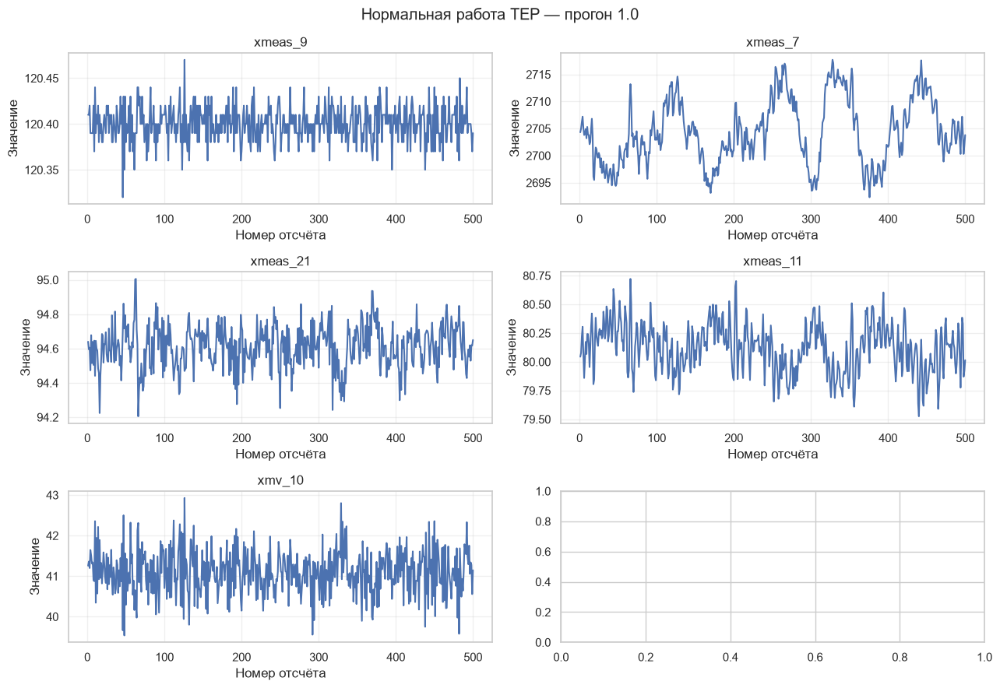

In [13]:
run_id = df_normal["simulationRun"].iloc[0]

normal_run = df_normal[df_normal["simulationRun"] == run_id].sort_values("sample")

selected_cols = [
    "xmeas_9",
    "xmeas_7",
    "xmeas_21",
    "xmeas_11",
    "xmv_10",
]

fig, axes = plt.subplots(3, 2, figsize=(13, 9))

for ax, col in zip(axes.flat, selected_cols):
    ax.plot(normal_run["sample"], normal_run[col])
    ax.set_title(col)
    ax.set_xlabel("Номер отсчёта")
    ax.set_ylabel("Значение")
    ax.grid(alpha=0.3)

plt.suptitle(f"Нормальная работа TEP — прогон {run_id}")
plt.tight_layout()
plt.show()

## 6. Сравним несколько нормальных прогонов

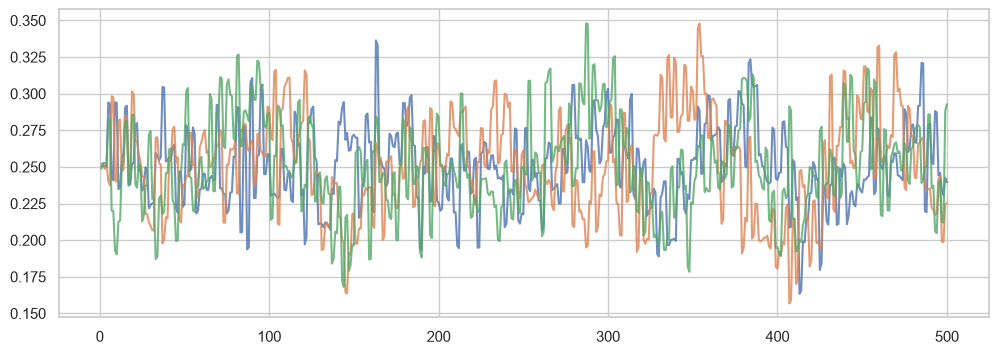

In [14]:
run_ids = df_normal["simulationRun"].unique()[:3]
signal = feature_cols[0]

plt.figure(figsize=(12, 4))

for run_id in run_ids:
    run = df_normal[df_normal["simulationRun"] == run_id].sort_values("sample")

    plt.plot(run["sample"], run[signal], label=f"Прогон {run_id}", alpha=0.8)

### Выводы по визуальному анализу нормальных режимов

Анализ временных рядов первых шести технологических параметров показал, что при нормальной работе системы значения изменяются во времени, преимущественно колеблясь вокруг относительно устойчивых уровней.

На рассмотренных графиках не наблюдается выраженных долгосрочных трендов, однако присутствуют кратковременные колебания, пики и провалы, характерные для динамической системы.

Сравнение трёх независимых прогонов по параметру `xmeas_1` показало сходный диапазон значений при различиях в конкретной динамике сигнала.

Таким образом, алгоритм поиска новизны должен учитывать естественную изменчивость нормальных временных рядов и не интерпретировать каждое кратковременное отклонение как неисправность.

Сделанные наблюдения относятся к выбранным параметрам и прогонам и требуют дальнейшей количественной проверки.

## 7. Анализ неисправных режимов

Цель - исследовать изменение технологических параметров при возникновении неисправности и сравнить их с нормальной работой.

 Загрузка неисправных данных

In [15]:
result_faulty = pyreadr.read_r(DATA_DIR / "TEP_Faulty_Testing.RData")

print("Объекты:", list(result_faulty.keys()))

df_faulty = next(iter(result_faulty.values()))

print("Размер:", df_faulty.shape)
display(df_faulty.head())

Объекты: ['faulty_testing']
Размер: (9600000, 55)


,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,xmeas_8,xmeas_9,xmeas_10,xmeas_11,xmeas_12,xmeas_13,xmeas_14,xmeas_15,xmeas_16,xmeas_17,xmeas_18,xmeas_19,xmeas_20,xmeas_21,xmeas_22,xmeas_23,xmeas_24,xmeas_25,xmeas_26,xmeas_27,xmeas_28,xmeas_29,xmeas_30,xmeas_31,xmeas_32,xmeas_33,xmeas_34,xmeas_35,xmeas_36,xmeas_37,xmeas_38,xmeas_39,xmeas_40,xmeas_41,xmv_1,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,1,1.0,1,0.25171,3672.4,4466.3,9.5122,27.057,42.473,2705.6,74.750,120.41,0.33642,80.185,50.671,2634.6,24.592,50.614,3102.5,24.119,65.764,231.94,341.27,94.660,77.137,32.188,8.8933,26.383,6.8820,18.776,1.6567,32.958,13.823,23.978,1.2565,18.579,2.2633,4.8436,2.2986,0.017866,0.8357,0.098577,53.724,43.828,62.908,54.494,24.527,59.710,22.357,40.149,40.074,47.955,47.300,42.100,15.345
1,1,1.0,2,0.25234,3642.2,4568.7,9.4145,26.999,42.586,2705.2,75.126,120.38,0.33801,80.104,49.508,2634.1,23.399,49.353,3102.3,23.817,65.729,229.67,341.76,94.558,77.130,32.188,8.8933,26.383,6.8820,18.776,1.6567,32.958,13.823,23.978,1.2565,18.579,2.2633,4.8436,2.2986,0.017866,0.8357,0.098577,53.724,43.828,63.429,53.269,24.465,60.466,22.413,39.956,36.651,45.038,47.502,40.553,16.063
2,1,1.0,3,0.24840,3643.1,4507.5,9.2901,26.927,42.278,2703.5,74.540,120.38,0.33702,79.988,51.280,2632.1,24.319,49.144,3100.7,21.973,65.708,229.94,341.47,94.732,77.168,32.492,8.9860,25.882,6.9881,18.750,1.6203,33.387,13.666,23.703,1.2234,18.834,2.2782,4.8584,2.3201,0.017866,0.8357,0.098577,53.724,43.828,63.412,54.000,24.860,60.642,22.199,40.074,41.868,44.553,47.479,41.341,20.452
3,1,1.0,4,0.25153,3628.3,4519.3,9.3347,26.999,42.330,2703.9,74.861,120.38,0.33648,79.957,50.668,2632.3,24.209,50.654,3101.3,23.378,65.692,230.42,341.38,94.466,77.147,32.492,8.9860,25.882,6.9881,18.750,1.6203,33.387,13.666,23.703,1.2234,18.834,2.2782,4.8584,2.3201,0.017866,0.8357,0.098577,53.724,43.828,63.668,53.860,24.553,61.908,21.981,40.141,40.066,48.048,47.440,40.780,17.123
4,1,1.0,5,0.21763,3655.8,4571.0,9.3087,26.901,42.402,2707.7,74.380,120.40,0.32114,80.261,50.066,2636.1,25.682,49.198,3102.2,22.692,65.723,229.42,341.53,94.770,77.868,32.396,8.9172,26.103,6.6982,18.333,1.6463,32.913,13.874,23.524,1.2179,18.527,2.2895,4.8113,2.2049,0.017866,0.8357,0.098577,53.724,43.828,62.213,53.307,21.775,61.891,22.412,37.696,38.295,44.678,47.530,41.089,18.681


Смотрим разметку

In [16]:
print("Типы неисправностей:")
print(sorted(df_faulty["faultNumber"].unique()))

print("\nКоличество прогонов по типам:")
display(df_faulty.groupby("faultNumber")["simulationRun"].nunique())

Типы неисправностей:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20)]

Количество прогонов по типам:


faultNumber
1     500
2     500
3     500
4     500
5     500
6     500
7     500
8     500
9     500
10    500
11    500
12    500
13    500
14    500
15    500
16    500
17    500
18    500
19    500
20    500
Name: simulationRun, dtype: int64

## Общая структура неисправных данных

In [17]:
fault_summary = df_faulty.groupby("faultNumber").agg(
    runs=("simulationRun", "nunique"), samples=("sample", "count")
)

fault_summary["samples_per_run"] = fault_summary["samples"] / fault_summary["runs"]

display(fault_summary)

,runs,samples,samples_per_run
faultNumber,,,
1,500,480000,960.0
2,500,480000,960.0
3,500,480000,960.0
4,500,480000,960.0
5,500,480000,960.0
6,500,480000,960.0
7,500,480000,960.0
8,500,480000,960.0
9,500,480000,960.0


Временные ряди с неисправностями и нормальной работой отличаются по длине (960 и 500 отсчётов соответственно) Нужно решить методологический вопрос как сравнивать такие временные ряды

## Посмотрим прогон неисправности № 4

Начнём с faultNumber = 4 — изменения температуры охлаждающей воды на входе реактора.


In [18]:
fault_run = df_faulty[
    (df_faulty["faultNumber"] == 4) & (df_faulty["simulationRun"] == 1)
].sort_values("sample")

print("Размер выбранного прогона:", fault_run.shape)

Размер выбранного прогона: (960, 55)


## Визуализация

Поскольку неисправность №4 связана с температурой охлаждающей воды реактора, рассмотрим показатели,которые физически связаны с этой неисправностью.


 - xmeas_9 - Температура реактора
- xmeas_7 -	Давление реактора
- xmeas_21 -	Температура охлаждающей воды на выходе реактора
- xmeas_11 -	Температура сепаратора
 - xmv_10 - Управление расходом охлаждающей воды реактора

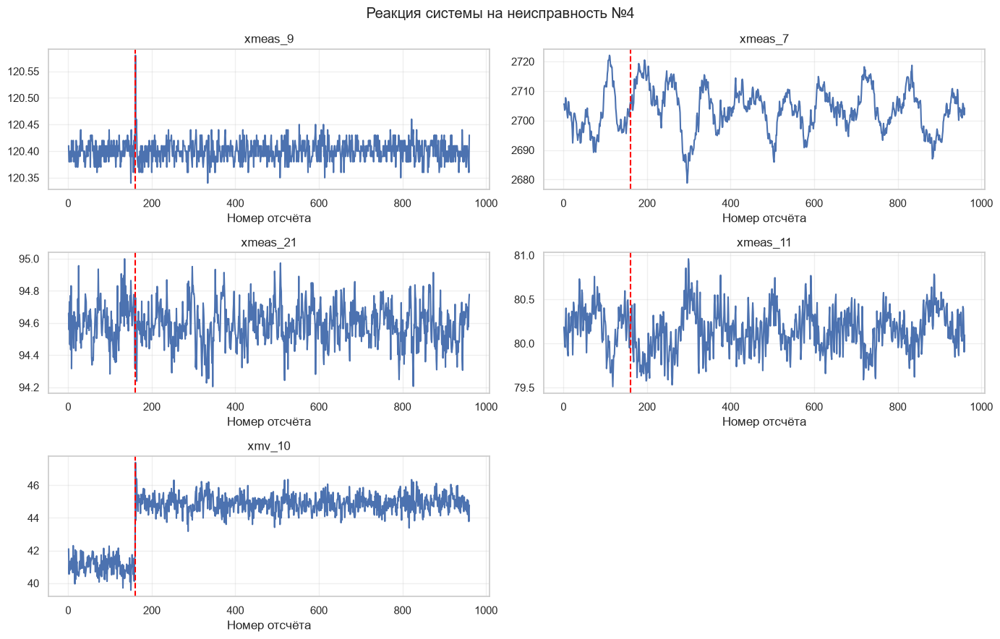

In [19]:
selected_cols = [
    "xmeas_9",
    "xmeas_7",
    "xmeas_21",
    "xmeas_11",
    "xmv_10",
]


import math

ncols = 2
nrows = math.ceil(len(selected_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3 * nrows))

for ax, col in zip(axes.flat, selected_cols):
    ax.plot(fault_run["sample"], fault_run[col])

    ax.axvline(160, color="red", linestyle="--")

    ax.set_title(col)
    ax.set_xlabel("Номер отсчёта")
    ax.grid(alpha=0.3)

# Убираем неиспользуемые области
for ax in axes.flat[len(selected_cols) :]:
    ax.set_visible(False)

plt.suptitle("Реакция системы на неисправность №4")
plt.tight_layout()
plt.show()

Заметно изменилось только управляющиее воздействие на подачу охлаждающей воды реактора, остальные показатели визуально не изменились, проверим наблюдение количественно

In [20]:
# До возникновения неисправности
before = fault_run[fault_run["sample"].between(1, 160)]

# После возникновения неисправности
after = fault_run[fault_run["sample"].between(161, 320)]

comparison = pd.DataFrame(
    {
        "mean_before": before[selected_cols].mean(),
        "mean_after": after[selected_cols].mean(),
        "std_before": before[selected_cols].std(),
    }
)

comparison["difference"] = comparison["mean_after"] - comparison["mean_before"]

# Изменение среднего в единицах исходного разброса
comparison["normalized_difference"] = comparison["difference"] / comparison[
    "std_before"
].replace(0, np.nan)

display(comparison.round(3))

,mean_before,mean_after,std_before,difference,normalized_difference
xmeas_9,120.399,120.400,0.018,0.001,0.059
xmeas_7,2701.585,2705.457,7.421,3.872,0.522
xmeas_21,94.607,94.590,0.134,-0.017,-0.123
xmeas_11,80.208,80.087,0.234,-0.121,-0.519
xmv_10,41.078,44.920,0.535,3.842,7.175


### Анализ неисправности №4

При исследовании неисправности №4 (скачкообразное изменение температуры охлаждающей воды на входе реактора) было обнаружено выраженное изменение управляющей переменной `xmv_10` после 160-го временного отсчёта.

При этом рассмотренные измеряемые параметры, включая температуру реактора `xmeas_9`, не демонстрируют сопоставимого  смещения.

Это связано с работой автоматической системы регулирования, которая компенсирует внешнее возмущение и поддерживает технологические параметры вблизи заданных значений.

Данное наблюдение указывает на потенциальную значимость управляющих переменных при обнаружении неисправностей и обосновывает необходимость сравнения моделей, использующих только измеряемые параметры, с моделями, дополнительно учитывающими управляющие воздействия.

## Неисправность № 6

Fault 6 — A Feed Loss (Stream 1), то есть потеря подачи исходного компонента A в реактор по потоку №1. В симуляторе это скачкообразное нарушение.
В отличие от неисправности №4, которая затрагивала охлаждение, здесь нарушается поступление реагента. Поэтому можно ожидать изменений расходов, управляющих воздействий и, возможно, параметров реактора.

Для анализа выберем следующие переменные:

- xmeas_1	Расход компонента A (поток №1)
- xmeas_4	Общий расход компонентов A и C (поток №4)
- xmeas_6	Общий расход сырья в реактор
- xmeas_7	Давление реактора
- xmeas_8	Уровень в реакторе
- xmeas_9	Температура реактора
- xmv_3	Управление подачей A (поток №1)
- xmv_4	Управление подачей A и C (поток №4)

Построим график неисправности

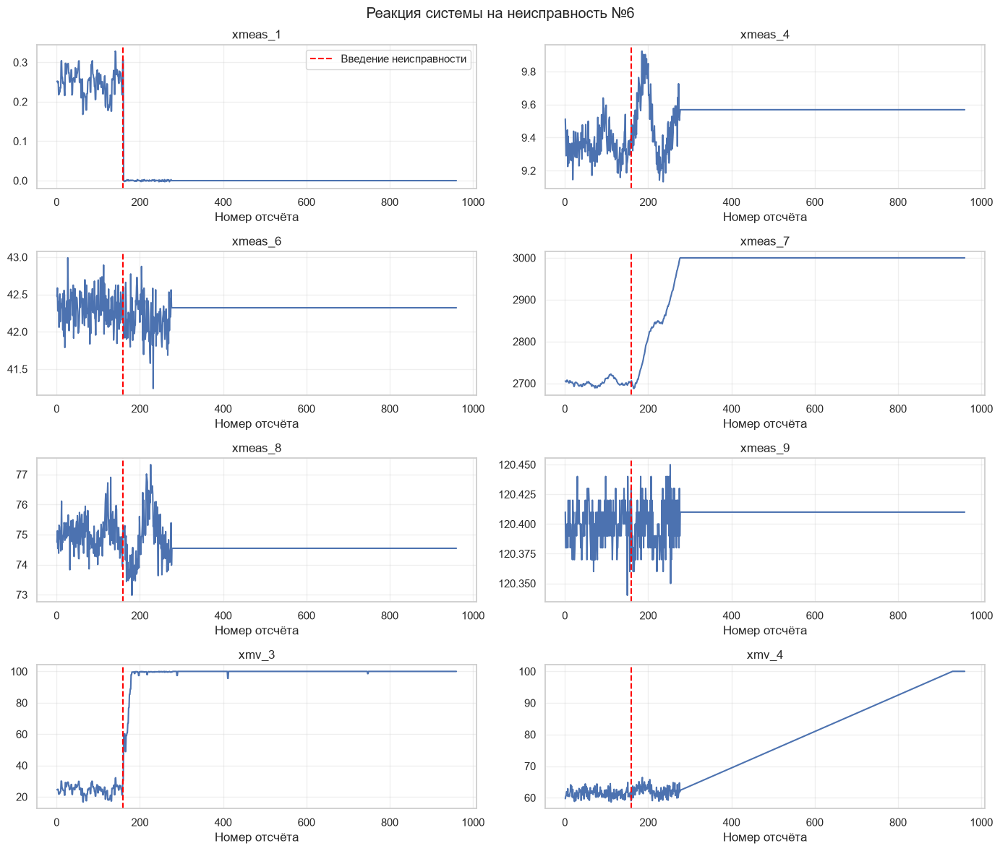

In [21]:
# Выбираем первый прогон неисправности №6
fault_6 = df_faulty[
    (df_faulty["faultNumber"] == 6) & (df_faulty["simulationRun"] == 1)
].sort_values("sample")

selected_cols_6 = [
    "xmeas_1",
    "xmeas_4",
    "xmeas_6",
    "xmeas_7",
    "xmeas_8",
    "xmeas_9",
    "xmv_3",
    "xmv_4",
]

fig, axes = plt.subplots(4, 2, figsize=(14, 12))

for ax, col in zip(axes.flat, selected_cols_6):
    ax.plot(fault_6["sample"], fault_6[col])

    ax.axvline(160, color="red", linestyle="--", label="Введение неисправности")

    ax.set_title(col)
    ax.set_xlabel("Номер отсчёта")
    ax.grid(alpha=0.3)

axes[0, 0].legend()

plt.suptitle("Реакция системы на неисправность №6")
plt.tight_layout()
plt.show()

In [22]:
before_6 = fault_6[fault_6["sample"].between(1, 160)]

after_6 = fault_6[fault_6["sample"].between(161, 320)]

comparison_6 = pd.DataFrame(
    {
        "mean_before": before_6[selected_cols_6].mean(),
        "mean_after": after_6[selected_cols_6].mean(),
        "std_before": before_6[selected_cols_6].std(),
    }
)

# Абсолютная разница
comparison_6["difference"] = comparison_6["mean_after"] - comparison_6["mean_before"]

# Относительное изменение, %
comparison_6["difference_pct"] = (
    comparison_6["difference"] / comparison_6["mean_before"].replace(0, np.nan) * 100
)

# Изменение относительно разброса до неисправности
comparison_6["normalized_difference"] = comparison_6["difference"] / comparison_6[
    "std_before"
].replace(0, np.nan)

display(comparison_6.round(3))

,mean_before,mean_after,std_before,difference,difference_pct,normalized_difference
xmeas_1,0.249,0.000,0.033,-0.249,-99.999,-7.468
xmeas_4,9.352,9.510,0.091,0.158,1.686,1.734
xmeas_6,42.323,42.212,0.212,-0.111,-0.263,-0.524
xmeas_7,2701.585,2877.527,7.421,175.942,6.513,23.710
xmeas_8,75.048,74.769,0.524,-0.279,-0.372,-0.533
xmeas_9,120.399,120.401,0.018,0.003,0.002,0.146
xmv_3,24.512,96.015,3.278,71.503,291.706,21.815
xmv_4,61.285,62.549,1.292,1.265,2.063,0.979


На графиках мы видим прямые, это связано с тем, что в стенде предусмотрено аварийное отключение установки при достижении предельного давления реактора 3000 кПа. На графике xmeas_7 это наглядно видно

## Выводы по разведочному анализу данных


В ходе EDA была исследована структура датасета Tennessee Eastman Process (TEP), предназначенного для анализа нормальных и неисправных режимов промышленного технологического процесса.

**Основные результаты:**

1. Обучающая выборка нормальной работы содержит 500 прогонов по 500 временных отсчётов. Каждый отсчёт характеризуется 52 технологическими параметрами.
2. В нормальных обучающих данных отсутствуют пропущенные значения и полные дубликаты строк.
3. При нормальной работе параметры колеблются вокруг относительно устойчивых значений. Разные прогоны демонстрируют сходные диапазоны значений, но различаются динамикой.
4. При неисправности №4 наиболее заметное изменение среди рассмотренных параметров наблюдается у управляющей переменной `xmv_10`, что может свидетельствовать о компенсации внешнего возмущения системой регулирования.
5. Неисправность №6 сопровождается прекращением подачи компонента A, существенным изменением управляющих воздействий и ростом давления реактора до аварийного предела 3000 кПа.
6. Наличие участков после аварийной остановки необходимо учитывать при формировании выборок для обучения и тестирования.

**Вывод для дальнейшего исследования**

Датасет TEP пригоден для исследования одноклассового поиска новизны в многомерных временных рядах.

В качестве базового подхода планируется использовать Isolation Forest, обучаемый на признаках, извлечённых из временных окон нормальной работы.

В дальнейшем предполагается сравнить базовый алгоритм с методами классификации временных рядов, адаптированными для одноклассового обучения.

Особое внимание необходимо уделить формированию временных окон, исключению утечек данных между выборками и оценке способности модели обнаруживать неисправности до аварийной остановки установки.